> **Version formatrice.** Tous les exercices sont complétés et le notebook a été exécuté. Les participants utilisent la version à compléter, à la racine du dossier.

# IA101 — Apprentissage machine avec Scikit-learn

## Notebook 0 — Motivation

**Calcul Québec** · Atelier en ligne · Durée de ce notebook : 10 minutes

L'atelier montre comment créer des modèles prédictifs avec scikit-learn et explore les principales méthodes de **classification**, de **prédiction** (régression) et de **détection de structures** dans les données. Il suit le programme annoncé :

1. **Motivation** (ce notebook)
2. **Introduction en douceur aux mathématiques de l'apprentissage machine** (notebook 1)
3. **Exercices et applications pratiques** (notebooks 2 à 6)

### Objectifs de l'atelier

À la fin de l'atelier, les participants seront en mesure de :

| # | Objectif | Partie du programme | Notebooks |
| --- | --- | --- | --- |
| O1 | Situer un problème dans la bonne famille de méthodes : classification, régression ou regroupement | Motivation | 0 |
| O2 | Expliquer le fonctionnement de l'apprentissage : modèle, fonction de perte, gradient, descente de gradient, généralisation | Mathématiques de l'apprentissage machine | 1 |
| O3 | Entraîner un modèle de classification ou de régression avec l'interface `fit` / `predict` / `score` de scikit-learn | Exercices et applications | 2, 6 |
| O4 | Évaluer un modèle avec une métrique adaptée au problème et au coût des erreurs | Exercices et applications | 3 |
| O5 | Améliorer un modèle de façon rigoureuse : prétraitement, validation croisée, recherche d'hyperparamètres | Exercices et applications | 4 |
| O6 | Détecter des structures dans des données non étiquetées : regroupement (k-moyennes) et réduction de dimension (ACP) | Exercices et applications | 5 |

### Prérequis

- Bonnes connaissances en statistiques : fonctions et dérivées.
- Programmation Python (niveau du cours PYT101).
- Analyse et visualisation de données avec NumPy, pandas et Matplotlib (niveau des cours DAT201 et DAT203).

### Déroulement (13 h 30 à 16 h 30)

| Heure | Notebook | Contenu |
| --- | --- | --- |
| 13 h 30 | 0 — Motivation | Programmation classique et apprentissage machine ; familles de problèmes |
| 13 h 40 | 1 — Mathématiques de l'apprentissage | Modèle, perte, gradient, descente de gradient, généralisation |
| 14 h 20 | 2 — Premier modèle de classification | Interface scikit-learn, k plus proches voisins, normalisation |
| 14 h 50 | *Pause* | |
| 15 h 00 | 3 — Évaluer un modèle | Matrice de confusion, précision, rappel, seuil de décision |
| 15 h 20 | 4 — Améliorer un modèle | Sous-apprentissage et surapprentissage, validation croisée, `GridSearchCV` |
| 15 h 50 | 5 — Détecter des structures | k-moyennes, analyse en composantes principales |
| 16 h 05 | 6 — Application intégratrice | Démarche complète sur un problème de régression |
| 16 h 25 | Synthèse | Questions, évaluation de l'atelier |

### Conventions utilisées dans les notebooks

| Mention | Signification |
| --- | --- |
| **Prédiction** | Avant d'exécuter la cellule, formulez votre hypothèse sur le résultat. |
| **Exercice** | Complétez les lignes marquées `# À COMPLÉTER`. Une solution repliable suit chaque exercice. |
| **Question de vérification** | Question à choix multiples avec rétroaction immédiate. |
| **À retenir** | Synthèse du notebook. |

Pour exécuter une cellule : sélectionnez-la, puis appuyez sur **Maj + Entrée**.

### Test de positionnement (2 minutes)

Répondez brièvement, sans recherche, dans la cellule suivante. Le même test est repris à la fin de l'atelier (notebook 6) afin de mesurer la progression.

1. Que « apprend » un modèle pendant l'entraînement ?
2. À quoi sert l'ensemble de test ?
3. Exactitude d'entraînement : 99 %. Exactitude de test : 70 %. Quel est le diagnostic ?
4. Pour un test de dépistage, quelle métrique faut-il surveiller en priorité ?
5. Nommez une pratique qui améliore un modèle et une pratique qui fausse son évaluation.

In [1]:
# Réponses au début de l'atelier
# 1.
# 2.
# 3.
# 4.
# 5.

In [2]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Programmation classique et apprentissage machine

En **programmation classique**, le développeur écrit explicitement les règles ; l'ordinateur les applique aux données.

En **apprentissage machine**, on fournit des **exemples** (des données accompagnées des réponses attendues) et un algorithme **estime les règles** à partir de ces exemples. Ces règles prennent la forme des **paramètres** d'un modèle.

Cette approche s'impose lorsque les règles sont inconnues, trop complexes pour être écrites à la main, ou changent dans le temps.

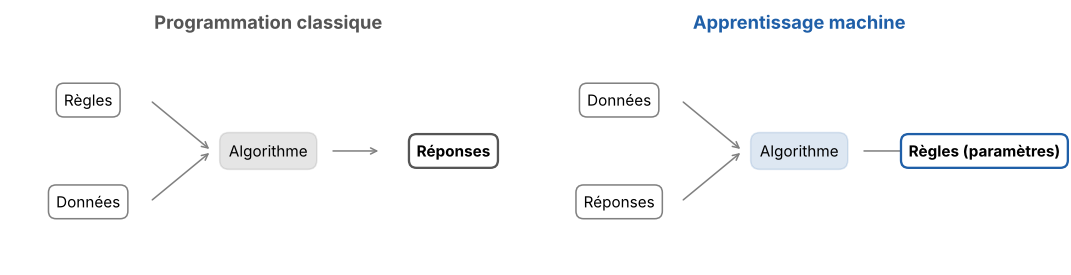

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
schemas = [
    ("Programmation classique", ["Règles", "Données"], "Réponses", "#555555"),
    ("Apprentissage machine",   ["Données", "Réponses"], "Règles (paramètres)", "#1f5fa8"),
]
for ax, (titre, entrees, sortie, couleur) in zip(axes, schemas):
    ax.set_xlim(0, 10); ax.set_ylim(0, 4); ax.axis("off")
    ax.set_title(titre, fontsize=12, fontweight="bold", color=couleur)
    for i, e in enumerate(entrees):
        ax.text(1.5, 2.9 - 1.8 * i, e, ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray"))
        ax.annotate("", xy=(3.9, 2.0), xytext=(2.7, 2.9 - 1.8 * i), arrowprops=dict(arrowstyle="->", color="gray"))
    ax.text(5, 2, "Algorithme", ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.6", fc=couleur, ec=couleur, alpha=0.15))
    ax.annotate("", xy=(7.2, 2), xytext=(6.2, 2), arrowprops=dict(arrowstyle="->", color="gray"))
    ax.text(8.6, 2, sortie, ha="center", va="center", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=couleur, lw=1.5))
plt.tight_layout(); plt.show()

### Exercice 1 — Écrire une règle, puis la faire estimer

On dispose de six observations :

| x | 1 | 2 | 3 | 4 | 5 | 6 |
| --- | --- | --- | --- | --- | --- | --- |
| y | 3 | 5 | 7 | 9 | 11 | 13 |

**a)** Écrivez la règle qui relie `x` à `y` (programmation classique).

**Corrigé**

In [5]:
def regle_ecrite(x):
    return 2 * x + 1

print("Pour x = 10, la règle écrite donne y =", regle_ecrite(10))

Pour x = 10, la règle écrite donne y = 21


**b)** Faites maintenant estimer cette règle par `LinearRegression`, à partir des seuls exemples. Toutes les méthodes de scikit-learn partagent la même interface :

1. **instancier** un estimateur ;
2. l'**entraîner** avec `.fit(X, y)` ;
3. **prédire** avec `.predict(X_nouveau)`.

`X` est toujours une matrice à deux dimensions : une ligne par observation, une colonne par variable.

**Corrigé**

In [6]:
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4], [5], [6]])
y = np.array([3, 5, 7, 9, 11, 13])

modele = LinearRegression()
modele.fit(X, y)
prediction = modele.predict([[10]])

print("Prédiction pour x = 10 :", prediction[0])
print(f"Règle estimée : y = {modele.coef_[0]:.2f} x + {modele.intercept_:.2f}")

Prédiction pour x = 10 : 21.0
Règle estimée : y = 2.00 x + 1.00


L'algorithme retrouve exactement `y = 2x + 1`. Les valeurs 2 et 1 sont les **paramètres** du modèle : ce sont elles qui ont été apprises.

Dans les applications réelles, la relation est **bruitée** et **inconnue**. Exemple : le délai d'arrivée d'une ambulance en fonction de la distance à parcourir dépend aussi de la circulation, de la météo et de l'heure. Aucune droite ne passe par tous les points ; il faut trouver la **meilleure** approximation. C'est l'objet du notebook 1.

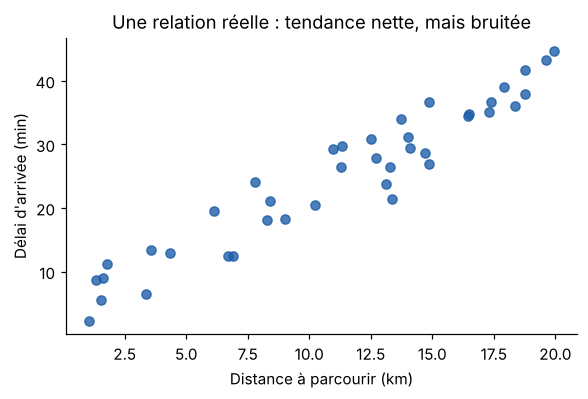

In [7]:
rng = np.random.default_rng(0)
distance = rng.uniform(1, 20, 40)
delai = 1.8 * distance + 4 + rng.normal(0, 3, 40)

plt.figure(figsize=(6, 3.5))
plt.scatter(distance, delai, color="#1f5fa8", alpha=0.8)
plt.xlabel("Distance à parcourir (km)"); plt.ylabel("Délai d'arrivée (min)")
plt.title("Une relation réelle : tendance nette, mais bruitée"); plt.show()

## 2. Les grandes familles de problèmes

| Famille | Question posée | Données d'entraînement | Exemples | Méthodes vues dans l'atelier |
| --- | --- | --- | --- | --- |
| **Classification** (supervisé) | À quelle catégorie appartient cette observation ? | Observations **et** catégories connues | Diagnostic bénin ou malin, type de vin, chiffre manuscrit | k plus proches voisins, régression logistique, arbres, forêts aléatoires |
| **Régression** (supervisé) | Quelle valeur numérique prédire ? | Observations **et** valeurs connues | Délai d'arrivée, progression d'une maladie, consommation énergétique | Régression linéaire, Ridge, forêts aléatoires |
| **Regroupement et réduction de dimension** (non supervisé) | Quelles structures ou tendances existent dans les données ? | Observations **sans** réponse | Segmentation de patients ou de clients, visualisation de données en grande dimension | k-moyennes, analyse en composantes principales |

Dans les méthodes **supervisées**, on connaît la bonne réponse pour les exemples d'entraînement. Dans les méthodes **non supervisées**, on cherche des structures sans réponse de référence.

In [8]:
quiz("Un hôpital souhaite prévoir le nombre d'appels d'urgence de la semaine prochaine. De quelle famille de problèmes s'agit-il ?",
     ["Classification", "Régression", "Regroupement"],
     1,
     "La cible est une valeur numérique : il s'agit d'un problème de régression (supervisé).")

**Question de vérification.** Un hôpital souhaite prévoir le nombre d'appels d'urgence de la semaine prochaine. De quelle famille de problèmes s'agit-il ?

RadioButtons(layout=Layout(width='max-content'), options=('Classification', 'Régression', 'Regroupement'), val…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

In [9]:
quiz("On dispose de dossiers de patients sans diagnostic, et l'on cherche des profils similaires. Quelle famille de méthodes convient ?",
     ["Classification", "Régression", "Regroupement (non supervisé)"],
     2,
     "Sans étiquette de référence, on cherche des structures dans les données : c'est un problème non supervisé.")

**Question de vérification.** On dispose de dossiers de patients sans diagnostic, et l'on cherche des profils similaires. Quelle famille de méthodes convient ?

RadioButtons(layout=Layout(width='max-content'), options=('Classification', 'Régression', 'Regroupement (non s…

Button(button_style='primary', description='Vérifier', style=ButtonStyle())

Output()

## À retenir

- **Programmation classique :** règles + données → réponses. **Apprentissage machine :** données + réponses → règles (paramètres du modèle).
- Trois grandes familles : **classification**, **régression** (supervisées) et **regroupement** (non supervisé).
- Interface commune de scikit-learn : instancier → `.fit(X, y)` → `.predict(X_nouveau)`.

**Notebook suivant :** 1 — Introduction aux mathématiques de l'apprentissage machine.